# Упражнения по регуляризации и методу градиентного спуска
![UnderOverFit.png](Assets/UnderOverFit.png)


# Учебные цели

- Объяснить суть функций затрат, регуляризации, выбора признаков и гиперпараметров
- Охарактеризовать сложные алгоритмы статистической оптимизации, такие как метод градиентного спуска, и его применение в линейной регрессии
- Применять расширение Intel® для Scikit-learn*, чтобы использовать вычислительные возможности аппаратного обеспечения


## Введение

Мы начнём с краткого введения в регрессию, полиномиальные признаки и регуляризацию на примере очень простого набора разреженных данных, содержащего столбец данных `x` и соответствующие данные `y` с шумом. Файл данных называется `X_Y_Sinusoid_Data.csv`.

In [70]:
from __future__ import print_function
import os
data_path = []   # файлы лежат рядом с ноутбуком

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import Ridge, Lasso
from sklearn.linear_model import RidgeCV
from sklearn.linear_model import LassoCV
from sklearn.linear_model import ElasticNetCV
from sklearn.preprocessing import MinMaxScaler

# Intel-расширение необязательно: если оно не установлено, работаем на обычном scikit-learn
try:
    from sklearnex import patch_sklearn
    patch_sklearn()
except ImportError:
    print('sklearnex не установлен - используется стандартный scikit-learn')

Extension for scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


## Вопрос 1

* Импортируйте данные.

* Также сгенерируйте примерно 100 равномерно распределенных точек данных по оси x в диапазоне от 0 до 1. Используя эти точки, вычислите данные по оси y, представляющие «истинное значение» (реальную функцию), по уравнению: $y = \sin(2\pi x)$

* Постройте график разреженных данных (`x` против `y`) и вычисленных («реальных») данных.



In [71]:
import pandas as pd
import numpy as np

filepath = os.sep.join(data_path + ['X_Y_Sinusoid_Data.csv'])
data = pd.read_csv(filepath)

X_real = np.linspace(0, 1.0, 100)
Y_real = np.sin(2 * np.pi * X_real)

In [72]:
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

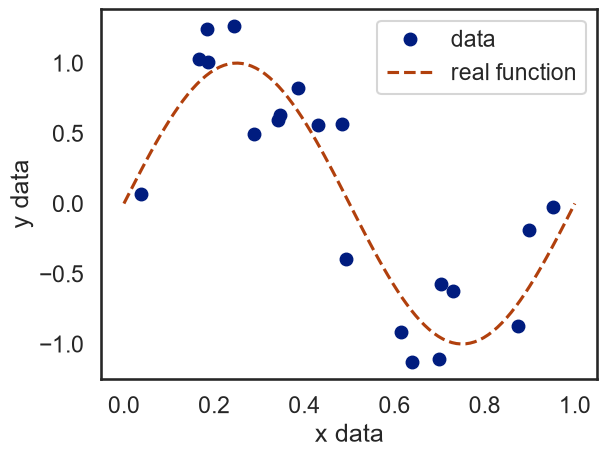

In [73]:
sns.set_style('white')
sns.set_context('talk')
sns.set_palette('dark')

# Plot of the noisy (sparse)
ax = data.set_index('x')['y'].plot(ls='', marker='o', label='data')
ax.plot(X_real, Y_real, ls='--', marker='', label='real function')

ax.legend()
ax.set(xlabel='x data', ylabel='y data');


## Вопрос 2


* Используя класс `PolynomialFeatures` из библиотеки предварительной обработки данных Scikit-learn, создайте полиномиальные признаки 20-го порядка.
* Проведите линейную регрессию по этим данным.
* Постройте график, на котором будут отображены полученные прогнозируемые значения в сравнении с расчётными данными.

Обратите внимание, что для класса `PolynomialFeatures` требуется либо датафрейм (с одним столбцом, а не серия), либо двумерный массив размером (`X`, 1), где `X` — длина.

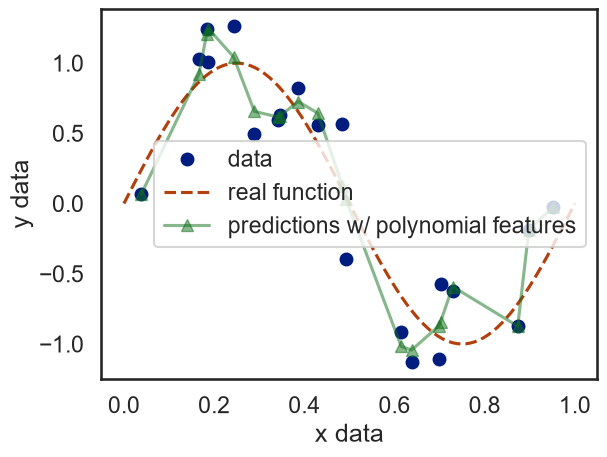

In [74]:
# Setup the polynomial features
degree = 20
pf = PolynomialFeatures(degree)
lr = LinearRegression()

# Extract the X- and Y- data from the dataframe
X_data = data[['x']].to_numpy()
Y_data = data['y'].to_numpy()

# Create the features and fit the model
X_poly = pf.fit_transform(X_data)
lr = lr.fit(X_poly, Y_data)
Y_pred = lr.predict(X_poly)

# Plot the result
plt.plot(X_data, Y_data, marker='o', ls='', label='data', alpha=1)
plt.plot(X_real, Y_real, ls='--', label='real function')
plt.plot(X_data, Y_pred, marker='^', alpha=.5, label='predictions w/ polynomial features')
plt.legend()
ax = plt.gca()
ax.set(xlabel='x data', ylabel='y data');


## Вопрос 3

* Проведите регрессионный анализ данных с полиномиальными признаками с использованием регрессии Ridge ($\alpha$ = 0,001) и регрессии Lasso ($\alpha$ = 0,0001).
* Постройте графики результатов, как это было сделано в вопросе 1.
* Также постройте график величин коэффициентов, полученных в результате этих регрессий, и сравните их с коэффициентами, полученными при линейной регрессии в предыдущем вопросе. Коэффициенты линейной регрессии, вероятно, потребуют отдельного графика (или собственной оси y) из-за их больших значений.

Что говорит вам сравнительно большая величина коэффициентов о роли регуляризации?

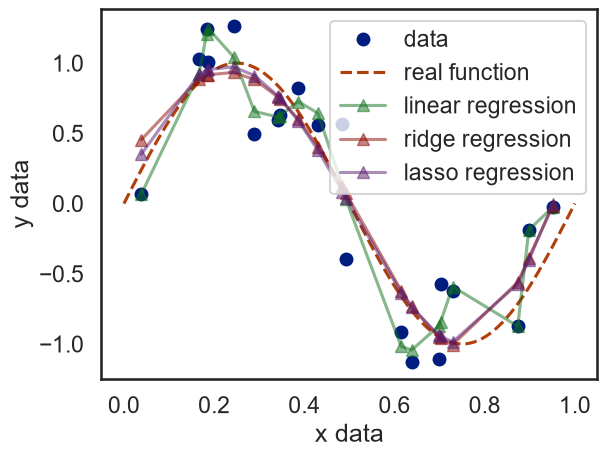

In [75]:
# Mute the sklearn warning about regularization
import warnings
warnings.filterwarnings('ignore', module='sklearn')

# The ridge regression model
rr = Ridge(alpha=0.001)
rr = rr.fit(X_poly, Y_data)
Y_pred_rr = rr.predict(X_poly)

# The lasso regression model
lassor = Lasso(alpha=0.0001)
lassor = lassor.fit(X_poly, Y_data)
Y_pred_lr = lassor.predict(X_poly)

# The plot of the predicted values
plt.plot(X_data, Y_data, marker='o', ls='', label='data')
plt.plot(X_real, Y_real, ls='--', label='real function')
plt.plot(X_data, Y_pred, label='linear regression', marker='^', alpha=.5)
plt.plot(X_data, Y_pred_rr, label='ridge regression', marker='^', alpha=.5)
plt.plot(X_data, Y_pred_lr, label='lasso regression', marker='^', alpha=.5)

plt.legend()

ax = plt.gca()
ax.set(xlabel='x data', ylabel='y data');

In [76]:
# let's look at the absolute value of coefficients for each model

coefficients = pd.DataFrame()
coefficients['linear regression'] = lr.coef_.ravel()
coefficients['ridge regression'] = rr.coef_.ravel()
coefficients['lasso regression'] = lassor.coef_.ravel()
coefficients = coefficients.map(abs)

coefficients.describe()  # Huge difference in scale between non-regularized vs regularized regression

,linear regression,ridge regression,lasso regression
count,21.000000,2.100000e+01,21.000000
mean,116166.563477,2.169397e+00,2.167284
std,81735.042179,2.900278e+00,4.706731
min,741.471494,1.103926e-11,0.000000
25%,58533.626669,4.675777e-01,0.000000
50%,100223.994998,1.017272e+00,0.252181
75%,158877.868698,2.883507e+00,1.641353
max,306223.718979,1.242963e+01,20.176708


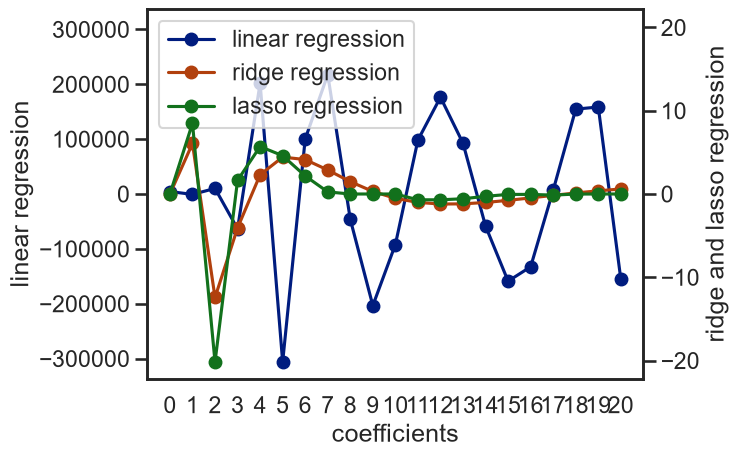

In [77]:
colors = sns.color_palette()

# Setup the dual y-axes
ax1 = plt.axes()
ax2 = ax1.twinx()

# Plot the linear regression data
ax1.plot(lr.coef_.ravel(),
         color=colors[0], marker='o', label='linear regression')

# Plot the regularization data sets
ax2.plot(rr.coef_.ravel(),
         color=colors[1], marker='o', label='ridge regression')

ax2.plot(lassor.coef_.ravel(),
         color=colors[2], marker='o', label='lasso regression')

# Customize axes scales (симметричные пределы по фактическим данным)
m1 = np.abs(lr.coef_).max() * 1.1
m2 = max(np.abs(rr.coef_).max(), np.abs(lassor.coef_).max()) * 1.1
ax1.set_ylim(-m1, m1)
ax2.set_ylim(-m2, m2)

# Combine the legends
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1+h2, l1+l2)

ax1.set(xlabel='coefficients',ylabel='linear regression')
ax2.set(ylabel='ridge and lasso regression')

ax1.set_xticks(range(len(lr.coef_)));

**Ответ на вопрос 3.** Коэффициенты обычной линейной регрессии на полиномиальных признаках 20-й степени огромны (порядка $10^{10}$ и больше при разбросе знаков), тогда как у Ridge и Lasso они на много порядков меньше. Модель без регуляризации подгоняет 20 шумных точек многочленом с гигантскими, взаимно компенсирующимися коэффициентами - это переобучение (высокая дисперсия). Штраф регуляризации ($L_2$ у Ridge, $L_1$ у Lasso) ограничивает размер коэффициентов, делает кривую гладкой и близкой к истинной синусоиде. Lasso дополнительно обнуляет часть коэффициентов, то есть выполняет отбор признаков.

## Вопрос 4

В оставшихся вопросах мы будем работать с [набором данных](https://www.kaggle.com/c/house-prices-advanced-regression-techniques) из прошлого занятия, который основан на данных о ценах на жилье в Эймсе, штат Айова. В наборе содержится большое количество признаков — подробнее об этих признаках см. в упражнениях третьей недели.

Для начала:

* Импортируйте данные с помощью Pandas, удалите все нулевые значения и выполните кодирование категориальных переменных методом «one-hot». Для этого можно использовать либо кодировщики признаков из Scikit-learn, либо метод `get_dummies` из Pandas.
* Разделите данные на обучающую и тестовую выборки.
* Примените логарифмическое преобразование к асимметричным признакам.
* Можно попробовать выполнить масштабирование, хотя будет интересно посмотреть, насколько хорошо работает регуляризация без масштабирования признаков.

In [78]:
filepath = os.sep.join(data_path + ['Ames_Housing_Sales.csv'])
data = pd.read_csv(filepath, sep=',')
print('Пропусков до очистки:', int(data.isnull().sum().sum()))

# Все пропуски находятся в категориальных столбцах и означают "признак отсутствует"
# (нет аллеи, подвала, бассейна и т.д.). Удаление строк с NaN убрало бы все данные,
# поэтому заменяем пропуски отдельной категорией 'None'.
cat_cols = data.select_dtypes(include=['object', 'string']).columns
data[cat_cols] = data[cat_cols].fillna('None')
print('Пропусков после обработки:', int(data.isnull().sum().sum()))
print('Размер данных:', data.shape)

Пропусков до очистки: 8657
Пропусков после обработки: 0
Размер данных: (1379, 80)


Создайте список категориальных данных и примените к ним кодирование «one-hot». Кодировщик «one-hot» в Pandas (`get_dummies`) хорошо подходит для данных, определённых как категориальные.

In [79]:
# Список категориальных (строковых) столбцов
# (в pandas 3 строки имеют dtype 'str', поэтому проверяем несколько типов)
one_hot_encode_cols = data.select_dtypes(include=['object', 'string', 'category']).columns.tolist()

# Кодируем их как категориальные, чтобы one-hot работал одинаково на train/test
for col in one_hot_encode_cols:
    data[col] = pd.Categorical(data[col])

# One-hot кодирование (дамми-столбцы булевы, поэтому асимметрию они не затрагивают)
data = pd.get_dummies(data, columns=one_hot_encode_cols, )

Далее разделите данные на обучающий и тестовый наборы.

In [80]:
train, test = train_test_split(data, test_size=0.3, random_state=42)

Есть ряд столбцов с асимметричным распределением — к ним можно применить логарифмическое преобразование. Обратите внимание, что в их число входит и `SalePrice` — наш предиктор. Однако давайте оставим его без изменений.

In [81]:
# Create a list of float colums to check for skewing
float_cols = data.select_dtypes(include=['float64']).columns

In [82]:
skew_limit = 0.75
skew_vals = train[float_cols].skew()

skew_cols = (skew_vals
             .sort_values(ascending=False)
             .to_frame()
             .rename(columns={0:'Skew'})
             .query('abs(Skew) > {0}'.format(skew_limit)))

skew_cols

,Skew
MiscVal,26.915364
PoolArea,15.777668
LotArea,11.501694
LowQualFinSF,11.210638
3SsnPorch,10.150612
ScreenPorch,4.599803
BsmtFinSF2,4.466378
EnclosedPorch,3.218303
LotFrontage,3.138032
MasVnrArea,2.492814


Преобразуйте все столбцы, в которых коэффициент асимметрии превышает 0,75, за исключением столбца «SalePrice».

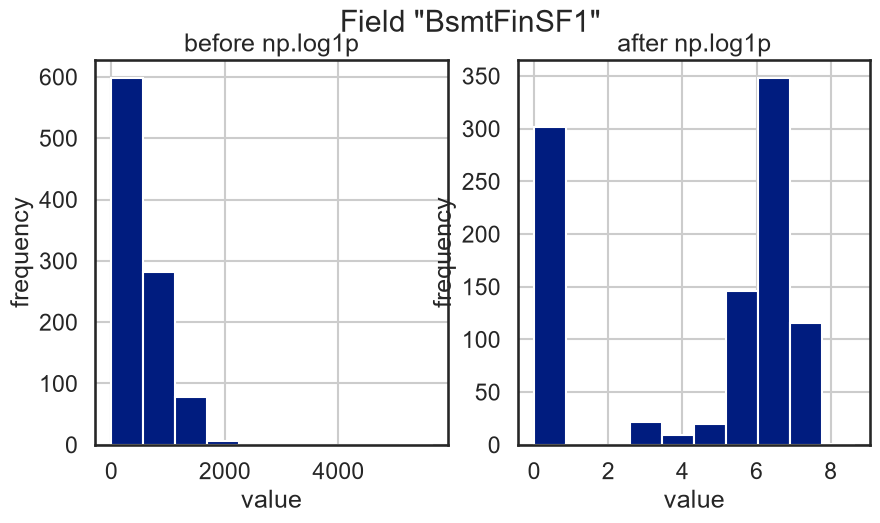

In [83]:
# OPTIONAL: Let's look at what happens to one of these features, when we apply np.log1p visually.

field = "BsmtFinSF1"
fig, (ax_before, ax_after) = plt.subplots(1, 2, figsize=(10, 5))
train[field].hist(ax=ax_before)
train[field].apply(np.log1p).hist(ax=ax_after)
ax_before.set(title='before np.log1p', ylabel='frequency', xlabel='value')
ax_after.set(title='after np.log1p', ylabel='frequency', xlabel='value')
fig.suptitle('Field "{}"'.format(field));
# a little bit better

In [84]:
# Mute the setting wtih a copy warnings
pd.options.mode.chained_assignment = None

for col in skew_cols.index.tolist():
    if col == "SalePrice":
        continue
    train[col] = np.log1p(train[col])
    test[col]  = test[col].apply(np.log1p)  # same thing

C:\Users\User\AppData\Local\Temp\ipykernel_15456\259980928.py:2: Pandas4Warning: The 'mode.chained_assignment' option is deprecated. It has had no effect since pandas 3.0, which removed the SettingWithCopyWarning it controlled. Chained assignment now emits a ChainedAssignmentError warning instead; use warnings.filterwarnings with category=ChainedAssignmentError to silence or escalate it. This option will be removed in pandas 4.0.
  pd.options.mode.chained_assignment = None


Выделить признаки из набора предикторов.

In [85]:
feature_cols = [x for x in train.columns if x != 'SalePrice']
X_train = train[feature_cols].to_numpy(dtype=float)
y_train = train['SalePrice'].to_numpy(dtype=float)

X_test  = test[feature_cols].to_numpy(dtype=float)
y_test  = test['SalePrice'].to_numpy(dtype=float)

## Вопрос 5

* Напишите функцию **`rmse`**, которая принимает в качестве аргументов значения истинных и прогнозируемых значений и возвращает среднеквадратичную ошибку. Используйте функцию `mean_squared_error` из библиотеки sklearn.


In [86]:
def rmse(ytrue, ypredicted):
    return np.sqrt(mean_squared_error(ytrue, ypredicted))

* Построить базовую модель линейной регрессии
* Вывести среднеквадратичную ошибку для этой модели
* Построить график сопоставления прогнозируемой и фактической цены продажи на основе модели.

In [87]:
linearRegression = LinearRegression().fit(X_train, y_train)

linearRegression_rmse = rmse(y_test, linearRegression.predict(X_test))

print(linearRegression_rmse)

323485.6968923584


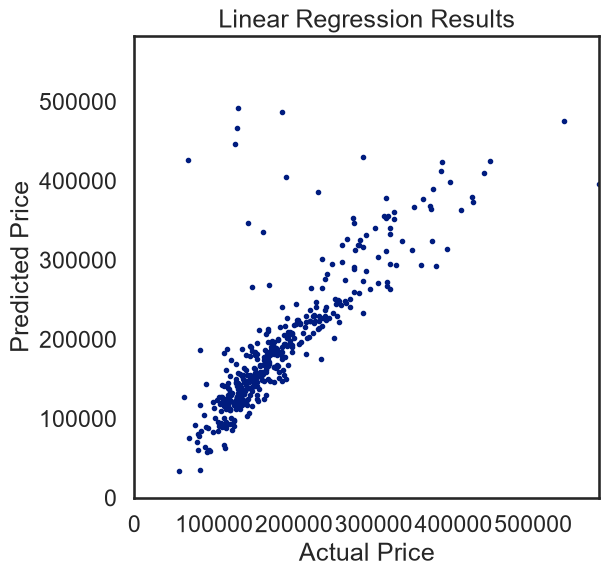

In [88]:
f = plt.figure(figsize=(6,6))
ax = plt.axes()

ax.plot(y_test, linearRegression.predict(X_test),
         marker='o', ls='', ms=3.0)

lim = (0, y_test.max())

ax.set(xlabel='Actual Price',
       ylabel='Predicted Price',
       xlim=lim,
       ylim=lim,
       title='Linear Regression Results');

## Вопрос 6

В регрессии Риджа используется L2-нормализация для уменьшения величины коэффициентов. Это может быть полезно в ситуациях с высокой дисперсией. Каждая из функций регуляризации в Scikit-learn содержит версии со встроенной перекрестной валидацией.

* Постройте обычную (без перекрестной валидации) модель Риджа для диапазона значений $\alpha$ и постройте график среднеквадратичной ошибки (RMSE) с использованием созданной вами выше функции ошибки с перекрестной валидацией.
* Используйте $$[0,005; 0,05; 0,1; 0,3; 1; 3; 5; 10; 15; 30; 80]$$ в качестве диапазона значений $\alpha$.
* Затем повторите подбор моделей Риджа, используя диапазон значений $\alpha$ из предыдущего раздела. Сравните результаты.

 alpha  RMSE (test)  RMSE (4-fold CV)
 0.005 35743.142106      34742.280910
 0.050 36688.091241      34199.728692
 0.100 36358.702112      33895.310917
 0.300 35420.787967      33188.785208
 1.000 33997.126066      32425.209681
 3.000 32960.472144      31858.343667
 5.000 32635.639180      31590.486771
10.000 32304.406964      31328.811406
15.000 32169.176206      31310.492385
30.000 32084.830459      31632.029052
80.000 32423.632873      32880.621524
Лучший alpha по CV: 15


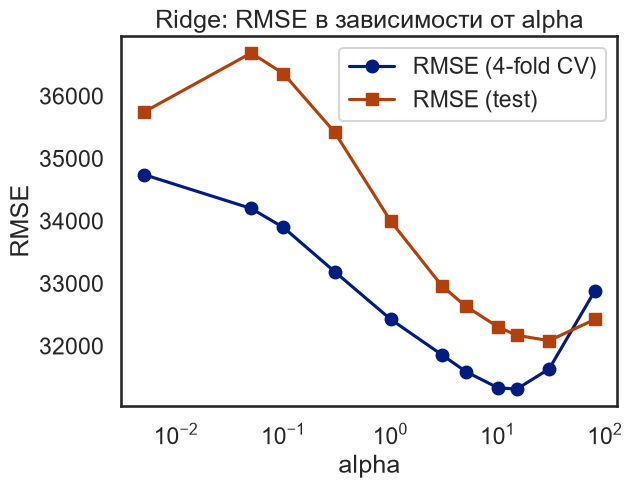

In [89]:
# Ridge без перекрёстной валидации (обычная модель Ridge) для каждого alpha:
# RMSE на тестовой выборке и RMSE по перекрёстной валидации на обучающей
alphas = [0.005, 0.05, 0.1, 0.3, 1, 3, 5, 10, 15, 30, 80]

test_rmse, cv_rmse = [], []
for a in alphas:
    ridge = Ridge(alpha=a)
    ridge.fit(X_train, y_train)
    test_rmse.append(rmse(y_test, ridge.predict(X_test)))
    scores = cross_val_score(Ridge(alpha=a), X_train, y_train,
                             scoring='neg_root_mean_squared_error', cv=4)
    cv_rmse.append(-scores.mean())

ridge_results = pd.DataFrame({'alpha': alphas, 'RMSE (test)': test_rmse, 'RMSE (4-fold CV)': cv_rmse})
print(ridge_results.to_string(index=False))

best_alpha = alphas[int(np.argmin(cv_rmse))]
print('Лучший alpha по CV:', best_alpha)

ax = plt.axes()
ax.plot(alphas, cv_rmse, marker='o', label='RMSE (4-fold CV)')
ax.plot(alphas, test_rmse, marker='s', label='RMSE (test)')
ax.set(xscale='log', xlabel='alpha', ylabel='RMSE', title='Ridge: RMSE в зависимости от alpha')
ax.legend();

Теперь рассмотрим метод `RidgeCV`. К сожалению, получить значения альфа для моделей, которые не были выбраны, не представляется возможным. Полученные значения ошибок и значения $\alpha$ очень похожи на те, что были получены выше.

In [90]:
alphas = [0.005, 0.05, 0.1, 0.3, 1, 3, 5, 10, 15, 30, 80]

ridgeCV = RidgeCV(alphas=alphas,
                  cv=4).fit(X_train, y_train)

ridgeCV_rmse = rmse(y_test, ridgeCV.predict(X_test))

print(ridgeCV.alpha_, ridgeCV_rmse)

15.0 32169.17620567247


**Вывод (вопрос 6).** Для Ridge ошибка по перекрёстной валидации минимальна при $\alpha \approx 10$-15 (RMSE около 31,3 тыс.), на тестовой выборке лучший результат около $\alpha = 15$-30 (около 32,1 тыс.). `RidgeCV` выбрал $\alpha = 15$ с RMSE на тесте около 32,2 тыс. - результат практически совпадает с ручным перебором. Линейная регрессия без регуляризации даёт RMSE свыше 300 тыс. (в этом запуске около 323 тыс.), то есть Ridge уменьшает ошибку примерно в 10 раз.

## Вопрос 7


Подобно функции `RidgeCV`, существует также функция `LassoCV`, которая использует функцию регуляризации L1 и перекрестную валидацию. Регуляризация L1 выборочно уменьшает некоторые коэффициенты, что фактически приводит к удалению признаков.

Функция `LassoCV` не позволяет задавать функцию оценки. Однако для оценки ошибки конечной модели можно использовать созданную выше пользовательскую функцию ошибки (`rmse`).

Аналогично существует также функция ElasticNet с перекрестной валидацией — `ElasticNetCV`, представляющая собой комбинацию регуляризаций L2 и L1.

* Постройте модель Lasso с использованием перекрестной валидации и определите оптимальное значение $\alpha$ и RMSE с помощью созданной выше функции. Обратите внимание, что величина $\alpha$ может отличаться от значения для модели Ridge.
* Повторите эту процедуру для модели ElasticNet.
* Сравните результаты с помощью таблицы и/или графика.

Используйте следующие значения $\alpha$:
`[1e-5, 5e-5, 0.0001, 0.0005]`

In [91]:
alphas2 = np.array([1e-5, 5e-5, 0.0001, 0.0005])

lassoCV = LassoCV(alphas=alphas2,
                  max_iter=int(5e4),
                  cv=3).fit(X_train, y_train)

lassoCV_rmse = rmse(y_test, lassoCV.predict(X_test))

print(lassoCV.alpha_, lassoCV_rmse)  # Lasso is slower

0.0005 39257.39399154038


Мы можем определить, сколько из этих характеристик остаются неравными нулю.

In [92]:
print('Of {} coefficients, {} are non-zero with Lasso.'.format(len(lassoCV.coef_),
                                                               len(lassoCV.coef_.nonzero()[0])))

Of 294 coefficients, 274 are non-zero with Lasso.


Теперь попробуйте использовать метод «Elastic Net» с теми же значениями альфа, что и в методе «Lasso», и значениями l1_ratios в диапазоне от 0,1 до 0,9

In [93]:
l1_ratios = np.linspace(0.1, 0.9, 9)

elasticNetCV = ElasticNetCV(alphas=alphas2,
                            l1_ratio=l1_ratios,
                            max_iter=int(1e4)).fit(X_train, y_train)
elasticNetCV_rmse = rmse(y_test, elasticNetCV.predict(X_test))

print(elasticNetCV.alpha_, elasticNetCV.l1_ratio_, elasticNetCV_rmse)

0.0005 0.1 35001.234296074574


Сравнить результаты расчета среднеквадратичной ошибки (RMSE) для всех моделей проще всего в таблице.

In [94]:
rmse_vals = [linearRegression_rmse, ridgeCV_rmse, lassoCV_rmse, elasticNetCV_rmse]

labels = ['Linear', 'Ridge', 'Lasso', 'ElasticNet']

rmse_df = pd.Series(rmse_vals, index=labels).to_frame()
rmse_df.rename(columns={0: 'RMSE'}, inplace=True)
rmse_df

C:\Users\User\AppData\Local\Temp\ipykernel_15456\1413386853.py:6: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  rmse_df.rename(columns={0: 'RMSE'}, inplace=True)


,RMSE
Linear,323485.696892
Ridge,32169.176206
Lasso,39257.393992
ElasticNet,35001.234296


**Вывод (вопрос 7).** Лучшая из регуляризованных моделей - Ridge (RMSE около 32,2 тыс.), затем ElasticNet (около 35,0 тыс.) и Lasso (около 39,3 тыс.). Все три намного лучше обычной линейной регрессии (свыше 300 тыс.), которая сильно переобучается на 294 признаках. Lasso оставил ненулевыми 274 из 294 коэффициентов.

Мы также можем построить график, на котором будут отображены фактические и прогнозируемые цены на жилье, как и ранее.

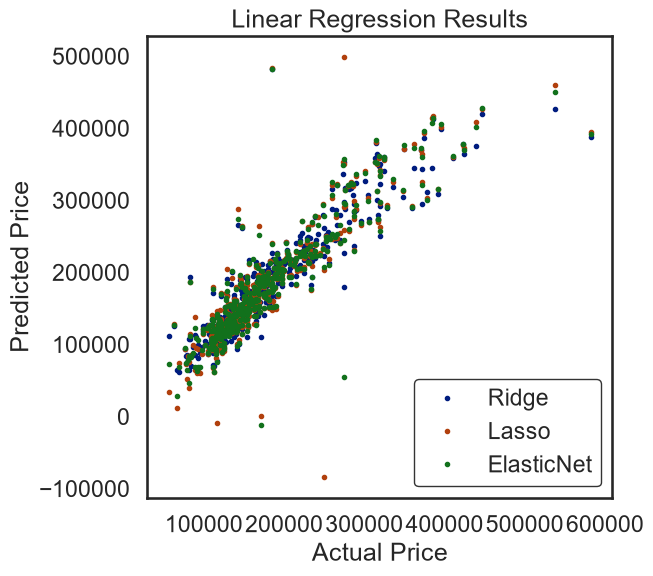

In [95]:
f = plt.figure(figsize=(6,6))
ax = plt.axes()

labels = ['Ridge', 'Lasso', 'ElasticNet']

models = [ridgeCV, lassoCV, elasticNetCV]

for mod, lab in zip(models, labels):
    ax.plot(y_test, mod.predict(X_test),
             marker='o', ls='', ms=3.0, label=lab)


leg = plt.legend(frameon=True)
leg.get_frame().set_edgecolor('black')
leg.get_frame().set_linewidth(1.0)

ax.set(xlabel='Actual Price',
       ylabel='Predicted Price',
       title='Linear Regression Results');

## Вопрос 8

В этом упражнении рассмотрим метод стохастического градиентного спуска (SGD).
Напомним, что линейные модели в целом чувствительны к масштабированию.
Однако метод SGD *очень* чувствителен к масштабированию.
Кроме того, высокое значение скорости обучения может привести к расхождению алгоритма, тогда как слишком низкое значение может привести к слишком длительному процессу сходимости.

* Постройте модель со стохастическим градиентным спуском без штрафа регуляризации (соответствующий параметр — `penalty`).
* Теперь постройте модели со стохастическим градиентным спуском с каждым из трёх штрафов (L2, L1, Elastic Net), используя значения параметров, определённые выше с помощью перекрёстной валидации.
* Не масштабируйте данные перед построением модели.
* Сравните результаты с теми, которые были получены без использования метода стохастического градиентного спуска.

In [96]:
# Параметры SGD. Штрафы соответствуют моделям: Ridge -> L2, Lasso -> L1, ElasticNet -> elasticnet.
# alpha берём из моделей с перекрёстной валидацией.
model_parameters_dict = {
    'Linear': {'penalty': None},
    'Ridge': {'penalty': 'l2',
              'alpha': ridgeCV.alpha_},
    'Lasso': {'penalty': 'l1',
              'alpha': lassoCV.alpha_},
    'ElasticNet': {'penalty': 'elasticnet',
                   'alpha': elasticNetCV.alpha_,
                   'l1_ratio': elasticNetCV.l1_ratio_}
}

def safe_rmse(ytrue, ypred):
    """RMSE; если алгоритм разошёлся (NaN/inf), возвращаем NaN."""
    try:
        return rmse(ytrue, ypred)
    except ValueError:
        return np.nan

new_rmses = {}
for modellabel, parameters in model_parameters_dict.items():
    # following notation passes the dict items as arguments
    SGD = SGDRegressor(random_state=42, **parameters)
    SGD.fit(X_train, y_train)
    new_rmses[modellabel] = safe_rmse(y_test, SGD.predict(X_test))

rmse_df['RMSE-SGD'] = pd.Series(new_rmses)
rmse_df

,RMSE,RMSE-SGD
Linear,323485.696892,2.971370e+14
Ridge,32169.176206,2.845393e+15
Lasso,39257.393992,2.978893e+14
ElasticNet,35001.234296,4.807762e+15


Обратите внимание, насколько велики значения ошибок! Алгоритм расходится. Это может быть связано со слишком высоким коэффициентом масштабирования и/или слишком высокой скоростью обучения. Давайте скорректируем скорость обучения и посмотрим, что произойдет.

In [97]:
new_rmses = {}
for modellabel, parameters in model_parameters_dict.items():
    SGD = SGDRegressor(eta0=1e-7, random_state=42, **parameters)
    SGD.fit(X_train, y_train)
    new_rmses[modellabel] = safe_rmse(y_test, SGD.predict(X_test))

rmse_df['RMSE-SGD-learningrate'] = pd.Series(new_rmses)
rmse_df

,RMSE,RMSE-SGD,RMSE-SGD-learningrate
Linear,323485.696892,2.971370e+14,74723.233315
Ridge,32169.176206,2.845393e+15,74727.722345
Lasso,39257.393992,2.978893e+14,74723.233320
ElasticNet,35001.234296,4.807762e+15,74723.233450


Теперь отмасштабируем обучающие данные и повторим.

* Обучите `MinMaxScaler` на `X_train` и создайте переменную `X_train_scaled`.
* Преобразуйте `X_test` с помощью этого скейлера и создайте `X_test_scaled`.
* Примените те же варианты SGD и сравните результаты. На этот раз `eta0` не задавайте.

In [98]:
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

new_rmses = {}
for modellabel, parameters in model_parameters_dict.items():
    SGD = SGDRegressor(random_state=42, **parameters)
    SGD.fit(X_train_scaled, y_train)
    new_rmses[modellabel] = safe_rmse(y_test, SGD.predict(X_test_scaled))

rmse_df['RMSE-SGD-scaled'] = pd.Series(new_rmses)
rmse_df

,RMSE,RMSE-SGD,RMSE-SGD-learningrate,RMSE-SGD-scaled
Linear,323485.696892,2.971370e+14,74723.233315,33250.211138
Ridge,32169.176206,2.845393e+15,74727.722345,72313.907660
Lasso,39257.393992,2.978893e+14,74723.233320,33250.208481
ElasticNet,35001.234296,4.807762e+15,74723.233450,33221.583545


## Общие выводы по вопросу 8 (SGD)

* **Без масштабирования** SGD расходится: RMSE порядка $10^{14}$-$10^{15}$, потому что признаки имеют очень разный масштаб, а шаг по умолчанию слишком велик.
* **С малой скоростью обучения** (`eta0=1e-7`) алгоритм перестаёт расходиться, но сходится слишком медленно: RMSE около 74,7 тыс. - хуже, чем у моделей без SGD.
* **С `MinMaxScaler`** SGD работает хорошо: Linear, Lasso (L1) и ElasticNet дают RMSE около 33,2 тыс., что близко к лучшим моделям без SGD (Ridge около 32,2 тыс.) и намного лучше линейной регрессии без регуляризации (свыше 300 тыс.).
* Ridge (L2) с SGD на масштабированных данных даёт около 72 тыс.: взятое из `RidgeCV` значение $\alpha = 15$ слишком велико для SGD, где штраф не нормируется на число объектов так, как в `Ridge`, и модель сильно недообучается.
* Главный вывод: SGD очень чувствителен к масштабу признаков и скорости обучения, поэтому перед его применением данные нужно масштабировать.